29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 62s 47ms/step - accuracy: 0.8518 - loss: 0.4144 - val_accuracy: 0.8814 - val_loss: 0.3177
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8903 - loss: 0.3024 - val_accuracy: 0.8933 - val_loss: 0.2913
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8989 - loss: 0.2751 - val_accuracy: 0.8993 - val_loss: 0.2803
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.9047 - loss: 0.2546 - val_accuracy: 0.8987 - val_loss: 0.2825
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.9097 - loss: 0.2366 - val_accuracy: 0.9033 - val_loss: 0.2753
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9162 - loss: 0.2234 - val_accuracy: 0.8984 - 

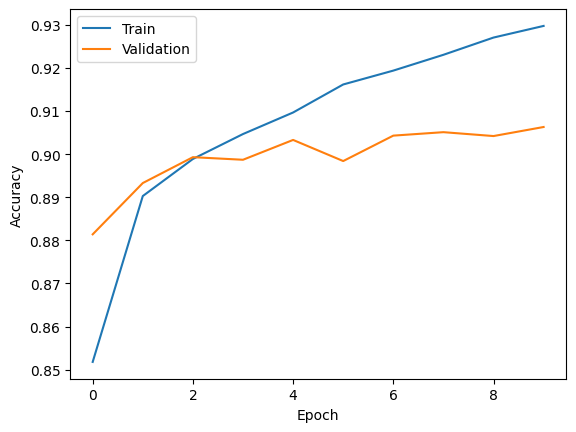

In [ ]:
# 1. Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 2. Load Fashion-MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# 3. Preprocess: grayscale -> RGB and resize
def preprocess(x, y):
    x = tf.expand_dims(x, -1)
    x = tf.image.grayscale_to_rgb(x)
    x = tf.image.resize(x, (96, 96))
    x = preprocess_input(x)
    return x, y

train = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train = train.shuffle(10000).map(preprocess).batch(64).prefetch(tf.data.AUTOTUNE)
test = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test = test.map(preprocess).batch(64).prefetch(tf.data.AUTOTUNE)

# 4. Load pretrained MobileNetV2
base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(96, 96, 3)
)
base.trainable = False

# 5. Add classifier
model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# 6. Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train,
    epochs=10,
    validation_data=test
)

# 7. Evaluate
loss, accuracy = model.evaluate(test)
print("Test Accuracy:", accuracy * 100, "%")

# 8. Plot accuracy
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()